# CFD Signal Forecasting with TensorFlow/Keras

This notebook uses Recurrent Neural Networks to forecast a turbulent signal:

- several time scales,
- oscillations,
- random noise,
- intermittent burst-like events.


The goal is to practice forcasting with real CFD data, see Cremades et al, Nature Communications, 2024.

```text
signal → input windows → future prediction → model comparison
```

The learning task is:

```text
Input:  previous values of u(t)
Output: future value of u(t)
```
We compare several methods:

```text
1. MLP
2. SimpleRNN
3. GRU
4. LSTM
```

We also use **EarlyStopping** to stop training automatically when the validation loss stops improving. Also, we are agoing to use TFRECORDS for the input data and Keras-style for the network.

# Stage 2 — Forecasting the near-wall signal with recurrent networks

**Portfolio project: forecasting a turbulent channel-flow signal with recurrent networks and a Transformer.**

This notebook cuts the Stage 1 signal into windows of 300 past values and 10 future values (stride 10, never across a file join), splits them in time (70 % training, 15 % validation, 15 % test), normalises with the training mean and standard deviation, and trains four networks with early stopping: a dense network on the flattened window, SimpleRNN, GRU and LSTM (hidden size 32). All are compared with persistence (the future equals the last value). I then solve the notebook's four exercises (forecast horizon, input length, hidden size, a second GRU layer), repeat every training with the seeds 0, 1 and 2, and record a training animation of the GRU.

**How it connects.** It reads `data/utmp_y50_raw_timeseries.h5` written by Stage 1 through `cfd_data_tools.py`. Stage 3 poses the same task to a Transformer on the same windows, and Stage 4 puts all networks on the same windows next to a linear autoregressive model fitted by least squares, which turns out to be far more accurate than any of them.

**About the outputs.** The outputs below come from my single run of this notebook (Apple M3 Max, 2026-10-13; dense and SimpleRNN on the CPU, GRU and LSTM on the Apple GPU, chosen by timing one training step on each). Afterwards I changed only text for this repository: this cell and the paths cell, the path lines (data from `../data/`, tables to `../results/02_recurrent_forecasting/`, checkpoints to `../models/02_recurrent_forecasting/`, animation to `../animations/02_*`), comments, labels (the original run labels renamed to "base") and printed text. One quirk is kept as written: the networks end in `Dense(1)` while each target holds 10 future values, so Keras compares one predicted value with all 10.

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
DATA_FILE = Path("../data/utmp_y50_raw_timeseries.h5")          # written by Stage 1
RESULTS = Path("../results/02_recurrent_forecasting")
MODELS = Path("../models/02_recurrent_forecasting")
for p in (RESULTS / "exercises", MODELS / "checkpoints", Path("../animations")): p.mkdir(parents=True, exist_ok=True)
print("processed signal present:", DATA_FILE.exists())

In [1]:
# Device report. Device per network from the step timing of 2026-10-13 (median of 30 training steps inside
# model.fit, batch 64, window 300; ../results/04_horizon_and_baselines/device_timing_*.csv): CPU vs Apple GPU, in ms per step
# Dense baseline 0.35 vs 5.97, SimpleRNN 8.6 vs 15,532, GRU 35.5 vs 17.7, LSTM 23.3 vs 18.2, stacked GRU 81 vs 26.
import tensorflow as tf, platform
NET_DEVICE = {"Dense baseline": "/CPU:0", "SimpleRNN": "/CPU:0", "GRU": "/GPU:0", "LSTM": "/GPU:0", "GRU x2": "/GPU:0"}
print("TensorFlow", tf.__version__, "| Python", platform.python_version())
print("Physical devices:", tf.config.list_physical_devices())
print("Device per network:", NET_DEVICE)

TensorFlow 2.18.1 | Python 3.12.14
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Device per network: {'Dense baseline': '/CPU:0', 'SimpleRNN': '/CPU:0', 'GRU': '/GPU:0', 'LSTM': '/GPU:0', 'GRU x2': '/GPU:0'}


# Environment

This notebook should run in:

- Google Colab,
- VS Code with Jupyter,
- a local Jupyter installation.

Required packages:

```bash
pip install numpy matplotlib tensorflow ipykernel
```

In [2]:
# =========================================================
# 1. Import libraries
# =========================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(0)
tf.random.set_seed(0)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.18.1


# Preparing the Forecasting Dataset

In this cell, we load the processed CFD time signal from an HDF5 file and prepare it for a forecasting problem.

The forecasting task is:

```text
300 past values → 10 future values
```

The class automatically creates input/output windows, splits the data into training, validation, and test sets, and normalizes everything using only the training statistics.

The resulting TensorFlow datasets are:

```text
train_ds → used to train the model
val_ds   → used during training to monitor validation error
test_ds  → used at the end for final evaluation
```

We also extract the NumPy arrays `X_train` and `y_train` to check their shapes and define:

```text
window_size   → number of input time steps
output_window → number of predicted future time steps
```

For this example, we expect:

```text
X_train.shape = (samples, 300, 1)
y_train.shape = (samples, 10)
```

In [3]:
# =========================================================
# Google Colab: mount Drive and move to project folder
# =========================================================

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    project_dir = Path('/content/drive/<Drive folder>/cfd-signal-forecasting-rnn-transformer/notebooks')
    data=Path('/content/drive/<Drive folder>/cfd-signal-forecasting-rnn-transformer/release_assets/raw_stp')

    %cd '/content/drive/<Drive folder>/cfd-signal-forecasting-rnn-transformer/notebooks'

    if str(project_dir) not in sys.path:
        sys.path.append(str(project_dir))

    print("Project directory:")
    print(project_dir)

    print("Data directory:")
    print(data)

    print("\nFiles:")
    for item in project_dir.iterdir():
        print(" -", item.name)

else:
    print("This is not Google Colab.")

This is not Google Colab.


In [4]:
from cfd_data_tools import CFDTimeSeriesLoader

loader = CFDTimeSeriesLoader(
    processed_dir="../data",
    y_index=50,
    variable="utmp"
)

loader.load_processed_h5("../data/utmp_y50_raw_timeseries.h5")

data = loader.prepare_forecasting_data(
    input_window=300,
    output_window=10,
    stride=10,
    batch_size=64
)

train_ds = data["train_ds"]
val_ds = data["val_ds"]
test_ds = data["test_ds"]

X_train = data["X_train"]
y_train = data["y_train"]

window_size = X_train.shape[1]
output_window = y_train.shape[1]


print(X_train.shape)
print(y_train.shape)

Processed HDF5 loaded from:
../data/utmp_y50_raw_timeseries.h5

Loaded arrays:
all_signal: (106000,)
all_timev: (106000,)
all_file_indices: (106000,)
Forecasting windows created:
X: (7419, 300, 1)
y: (7419, 10)


Normalization statistics:
signal_mean: 0.9274324
signal_std: 0.10147347
(5193, 300, 1)
(5193, 10)


2026-10-13 13:44:17.556110: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-13 13:44:17.556131: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-13 13:44:17.556137: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1791913457.556148 48544914 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791913457.556165 48544914 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


# Baseline: Persistence Model

Before training neural networks, we define a simple baseline.

The persistence model assumes:

```text
future value = last available value
```

In other words:

```text
u(t + horizon) ≈ u(t)
```

A neural network should be compared against this simple baseline.

In [5]:
# =========================================================
# 6. Prepare test arrays for the persistence baseline
# =========================================================

# These arrays come from loader.prepare_forecasting_data(...)
# They are already normalized using training statistics only.

X_test_norm = data["X_test"]
y_test_norm = data["y_test"]

print("X_test_norm shape:", X_test_norm.shape)
print("y_test_norm shape:", y_test_norm.shape)

X_test_norm shape: (1114, 300, 1)
y_test_norm shape: (1114, 10)


In [6]:
# =========================================================
# 7. Persistence baseline
# =========================================================

# Last value in each input window
last_value_test_norm = X_test_norm[:, -1, 0].reshape(-1, 1)

# MAE in normalized units
persistence_mae_norm = np.mean(
    np.abs(y_test_norm - last_value_test_norm)
)

print("Persistence baseline MAE:", persistence_mae_norm)

Persistence baseline MAE: 0.1027811


# Early Stopping and Helper Functions

We will train several models.

To avoid overfitting and unnecessary training, we use `EarlyStopping`.

It monitors the validation loss.

If the validation loss does not improve for several epochs, training stops automatically.

In [7]:
# =========================================================
# 8. Helper functions
# =========================================================

def create_early_stopping():
    """
    Create a fresh EarlyStopping callback.

    We create a new callback for each model.
    """

    return tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )


def plot_training(history, title):
    """
    Plot training and validation loss.
    """

    plt.figure(figsize=(8, 5))

    plt.plot(history.history["loss"], label="Training MAE")
    plt.plot(history.history["val_loss"], label="Validation MAE")

    plt.xlabel("Epoch")
    plt.ylabel("MAE")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


def compile_regression_model(model, learning_rate=0.001):
    """
    Compile a model for regression.
    """

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mae",
        metrics=["mae"]
    )

    return model

# Forecasting Models

We will compare several methods:

```text
1. Dense baseline
2. SimpleRNN
3. GRU
4. LSTM
```

All models receive the same input:

```text
previous 300 values of u(t)
```

and predict:

```text
future value of u(t)
```

# Recurrent Layers for Time-Series Forecasting

Recurrent layers are designed to process sequential data.

In our case, the input has the form:

```text
(batch, time, features)
```

For the CFD signal forecasting problem:

```text
(batch, 300, 1)
```

where:

```text
300 → number of past time steps
1   → one scalar signal value at each time step
```

A recurrent layer reads the input sequence and creates an internal representation of the past.

This representation is then used to predict the future signal.

A simple recurrent model has the structure:

```text
past signal window
    ↓
recurrent layer
    ↓
Dense layer
    ↓
future signal window
```

The final `Dense` layer must match the number of future values we want to predict:

```python
tf.keras.layers.Dense(output_window)
```

If:

```text
output_window = 10
```

then the model predicts:

```text
10 future values
```

The most important recurrent-layer parameters are:

```text
units              → size of the internal memory
return_sequences   → return all time steps or only the last one
dropout            → regularization on the input connections
recurrent_dropout  → regularization on the recurrent connections
activation         → nonlinear activation inside the layer
```

For our first models, the most important parameter to change is usually:

```python
units
```

For example:

```python
tf.keras.layers.GRU(32)
tf.keras.layers.GRU(64)
tf.keras.layers.GRU(128)
```

Larger models can learn more complex dynamics, but they are slower and may overfit more easily.

# Simple RNN Layer

A Simple RNN is the most basic recurrent neural network layer.

It processes a sequence one time step at a time and updates an internal hidden state.

For a CFD time signal, the input has the shape:

```text
(batch, time, features)
```

In our case:

```text
(batch, 300, 1)
```

A typical Simple RNN layer is:

```python
tf.keras.layers.SimpleRNN(hidden_size)
```

The most important parameter is:

```python
hidden_size
```

or equivalently:

```python
units
```

It controls the size of the hidden state.

For example:

```python
tf.keras.layers.SimpleRNN(32)
tf.keras.layers.SimpleRNN(64)
tf.keras.layers.SimpleRNN(128)
```

## Important parameters

```text
units
```

Number of hidden units. Larger values increase the capacity of the model.

```text
activation
```

Activation function used to update the hidden state.

The default is:

```python
activation="tanh"
```

For a first model, it is usually better to keep the default value.

```text
return_sequences
```

If `False`, the layer returns only the last output:

```text
(batch, units)
```

If `True`, the layer returns one output per time step:

```text
(batch, time, units)
```

This is needed when stacking recurrent layers.

```python
tf.keras.layers.SimpleRNN(
    64,
    return_sequences=True
)
```

```text
dropout
```

Regularization applied to the input connections.

```python
dropout=0.1
```

```text
recurrent_dropout
```

Regularization applied to the recurrent connections.

For a first model, it is usually better to keep:

```python
recurrent_dropout=0.0
```

## Recommended first Simple RNN model

```python
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(window_size, 1)),

    tf.keras.layers.SimpleRNN(
        units=64,
        activation="tanh",
        dropout=0.1,
        recurrent_dropout=0.0,
        return_sequences=False
    ),

    tf.keras.layers.Dense(output_window)
])
```

The final layer predicts the complete future window:

```text
output shape = (batch, output_window)
```

## Main limitation

Simple RNNs are useful for learning short temporal dependencies.

However, they often struggle with long sequences because the gradients can vanish during training.

For this reason, GRU and LSTM layers are usually more effective for longer or more complex time signals.

In practice, we use Simple RNN as a reference model, and then compare it with:

```text
GRU
LSTM
Transformer
```

# GRU Layer

GRU means **Gated Recurrent Unit**.

It is a recurrent layer similar to an LSTM, but usually simpler and lighter.

A GRU uses gates to decide how much past information should be kept and how much new information should be added.

A typical GRU layer is:

```python
tf.keras.layers.GRU(hidden_size)
```

The most important parameter is:

```python
hidden_size
```

or equivalently:

```python
units
```

It controls the size of the internal representation.

For example:

```python
tf.keras.layers.GRU(32)
tf.keras.layers.GRU(64)
tf.keras.layers.GRU(128)
```

The most important GRU options are:

```python
tf.keras.layers.GRU(
    units=64,
    activation="tanh",
    recurrent_activation="sigmoid",
    dropout=0.1,
    recurrent_dropout=0.0,
    return_sequences=False,
    reset_after=True
)
```

## Important parameters

```text
units
```

Number of internal units. This controls the capacity of the model.

```text
return_sequences
```

If `False`, the GRU returns only the last output:

```text
(batch, units)
```

If `True`, the GRU returns the full sequence:

```text
(batch, time, units)
```

This is necessary when stacking GRU layers.

```python
tf.keras.layers.GRU(
    64,
    return_sequences=True
)
```

```text
dropout
```

Regularization applied to the input connections.

```python
dropout=0.1
```

```text
recurrent_dropout
```

Regularization applied to the recurrent state. It can slow down training on GPU.

For a first model, it is usually better to keep:

```python
recurrent_dropout=0.0
```

```text
reset_after
```

Internal GRU convention. For most TensorFlow/Keras models, keep:

```python
reset_after=True
```

## Recommended first GRU model

```python
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(window_size, 1)),

    tf.keras.layers.GRU(
        units=64,
        dropout=0.1,
        recurrent_dropout=0.0,
        return_sequences=False,
        reset_after=True
    ),

    tf.keras.layers.Dense(output_window)
])
```

The final layer predicts the complete future window:

```text
output shape = (batch, output_window)
```

GRUs are often a good first choice for CFD time-series forecasting because they are lighter than LSTMs and usually train faster.

# LSTM Layer

LSTM means **Long Short-Term Memory**.

It is a recurrent layer designed to learn temporal dependencies in sequential data.

Compared with a basic RNN, an LSTM has an internal memory cell and several gates that control how information is stored, updated, and forgotten.

A typical LSTM layer is:

```python
tf.keras.layers.LSTM(hidden_size)
```

The most important parameter is:

```python
hidden_size
```

or equivalently:

```python
units
```

It controls the size of the internal memory representation.

For example:

```python
tf.keras.layers.LSTM(32)
tf.keras.layers.LSTM(64)
tf.keras.layers.LSTM(128)
```

The most important LSTM options are:

```python
tf.keras.layers.LSTM(
    units=64,
    activation="tanh",
    recurrent_activation="sigmoid",
    dropout=0.1,
    recurrent_dropout=0.0,
    return_sequences=False
)
```

## Important parameters

```text
units
```

Number of internal memory units. Larger values increase model capacity.

```text
return_sequences
```

If `False`, the layer returns only the last output:

```text
(batch, units)
```

If `True`, the layer returns one output per time step:

```text
(batch, time, units)
```

This is needed when stacking recurrent layers.

```python
tf.keras.layers.LSTM(
    64,
    return_sequences=True
)
```

```text
dropout
```

Regularization applied to the input connections.

```python
dropout=0.1
```

```text
recurrent_dropout
```

Regularization applied to the recurrent connections. It can make training slower, especially on GPU.

For a first model, it is usually better to keep:

```python
recurrent_dropout=0.0
```

## Recommended first LSTM model

```python
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(window_size, 1)),

    tf.keras.layers.LSTM(
        units=64,
        dropout=0.1,
        recurrent_dropout=0.0,
        return_sequences=False
    ),

    tf.keras.layers.Dense(output_window)
])
```

The final layer predicts the complete future window:

```text
output shape = (batch, output_window)
```

In [8]:
# =========================================================
# 9. Model definitions
# =========================================================

def create_dense_baseline(window_size):
    """
    Dense baseline.

    This model flattens the input window.
    It does not explicitly model the time order.
    """

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(window_size, 1)),
        tf.keras.layers.Flatten(),

        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(64, activation="relu"),

        tf.keras.layers.Dense(1)
    ])

    return compile_regression_model(model)


def create_simple_rnn(window_size, hidden_size=32):
    """
    Simple recurrent neural network.
    """

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(window_size, 1)),

        tf.keras.layers.SimpleRNN(hidden_size),

        tf.keras.layers.Dense(1)
    ])

    return compile_regression_model(model)


def create_gru(window_size, hidden_size=32):
    """
    GRU model.

    GRU uses gates to help remember or forget information.
    """

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(window_size, 1)),

        tf.keras.layers.GRU(hidden_size),

        tf.keras.layers.Dense(1)
    ])

    return compile_regression_model(model)


def create_lstm(window_size, hidden_size=32):
    """
    LSTM model.

    LSTM uses gates and a memory cell.
    It is often useful for sequence prediction.
    """

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(window_size, 1)),

        tf.keras.layers.LSTM(hidden_size),

        tf.keras.layers.Dense(1)
    ])

    return compile_regression_model(model)

# Train and Compare Models

Each model is trained using the same training and validation datasets.

We use early stopping for all models.

**Hook before the training cell.** Checkpoints for the base training (best model by validation loss and a periodic checkpoint every max(1, max_epochs // 10) epochs, in `../models/02_recurrent_forecasting/checkpoints/`), and, for the GRU only, a snapshot collector for the training animation, so the animation comes from the base run (no second training). The notebook's training cell passes these callbacks in addition to its own early stopping; nothing else about training changes.

In [9]:
import os, re
from pathlib import Path
EX_CKPT = Path("../models/02_recurrent_forecasting/checkpoints"); EX_CKPT.mkdir(parents=True, exist_ok=True)
EX_BUDGET = float(os.environ.get("EX_BUDGET_SCALE", "1"))
class ExPeriodicCheckpoint(tf.keras.callbacks.Callback):
    def __init__(self, path, every): super().__init__(); self.path, self.every = path, max(1, int(every))
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.every == 0: self.model.save_weights(str(self.path))
class ExAnimSnapshots(tf.keras.callbacks.Callback):
    def __init__(self, X, y): super().__init__(); self.X, self.y = X, y; self.snaps = []; self.loss = []; self.val = []
    def _snap(self, e): self.snaps.append(dict(epoch=e, pred=self.model(self.X, training=False).numpy()[:, 0], loss=list(self.loss), val=list(self.val)))
    def on_train_begin(self, logs=None): self._snap(0)
    def on_epoch_end(self, epoch, logs=None): self.loss.append(logs["loss"]); self.val.append(logs["val_loss"]); self._snap(epoch + 1)
ANIM_CB = None
def ex_base_callbacks(name):
    global ANIM_CB
    tag = re.sub(r"[^A-Za-z0-9]+", "_", name)
    cbs = [tf.keras.callbacks.ModelCheckpoint(str(EX_CKPT / f"{tag}_best.weights.h5"), monitor="val_loss", save_best_only=True, save_weights_only=True),
           ExPeriodicCheckpoint(EX_CKPT / f"{tag}_periodic.weights.h5", max_epochs // 10)]
    if name == "GRU":
        ANIM_CB = ExAnimSnapshots(X_test_norm[:400], np.asarray(y_test_norm)[:400]); cbs.append(ANIM_CB)
    return cbs


Training: Dense baseline


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        19,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,489 (91.75 KB)

 Trainable params: 23,489 (91.75 KB)

...

82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 420us/step - loss: 0.0903 - mae: 0.0903 - val_loss: 0.0965 - val_mae: 0.0965


Epoch 59/100


 1/82 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0882 - mae: 0.0882

82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 423us/step - loss: 0.0887 - mae: 0.0887 - val_loss: 0.0950 - val_mae: 0.0950


Dense baseline test MAE: 0.0986


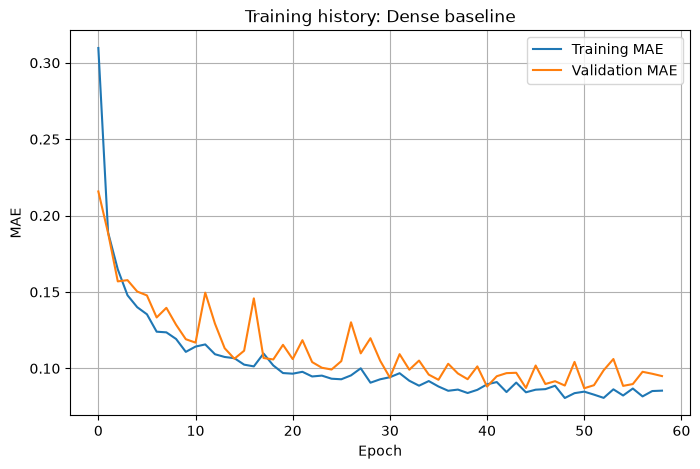


Training: SimpleRNN


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

...

71/82 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0606 - mae: 0.0606

76/82 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0605 - mae: 0.0605

81/82 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0605 - mae: 0.0605

82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0604 - mae: 0.0604 - val_loss: 0.0598 - val_mae: 0.0598


SimpleRNN test MAE: 0.0620


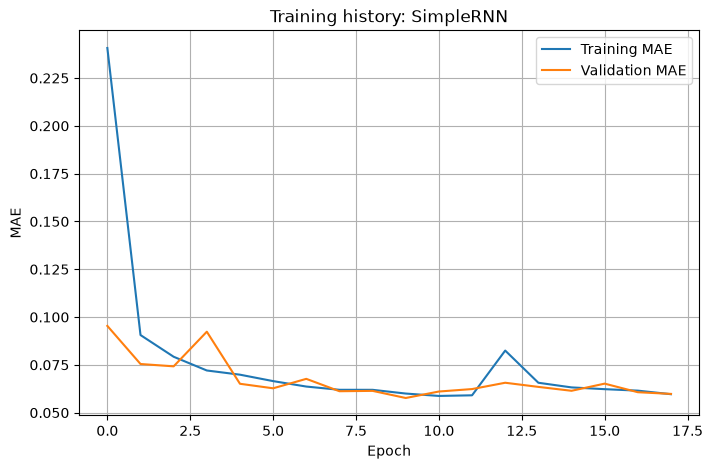


Training: GRU


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

...

75/82 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0627 - mae: 0.0627

78/82 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0627 - mae: 0.0627

81/82 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0626 - mae: 0.0626

82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0626 - mae: 0.0626 - val_loss: 0.0617 - val_mae: 0.0617


GRU test MAE: 0.0530


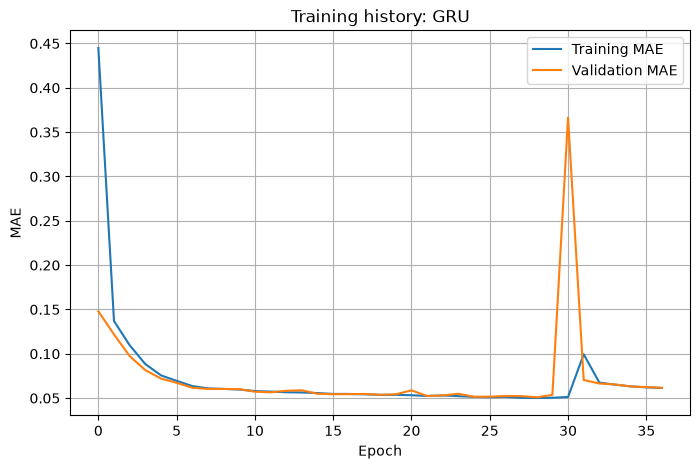


Training: LSTM


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

...

75/82 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0559 - mae: 0.0559

78/82 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0558 - mae: 0.0558

81/82 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0558 - mae: 0.0558

82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0558 - mae: 0.0558 - val_loss: 0.0532 - val_mae: 0.0532


LSTM test MAE: 0.0536


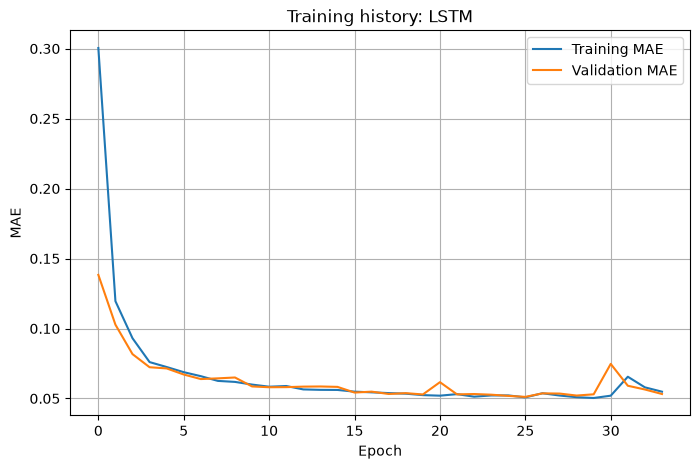

In [10]:
# =========================================================
# Train and compare models
# =========================================================

max_epochs = 100

# [original] models = {
# [original]     "Dense baseline": create_dense_baseline(window_size),
# [original]     "SimpleRNN": create_simple_rnn(window_size, hidden_size=32),
# [original]     "GRU": create_gru(window_size, hidden_size=32),
# [original]     "LSTM": create_lstm(window_size, hidden_size=32),
# [original] }
models = {}  # modified: each model is built on the device that trains it fastest (NET_DEVICE, device cell at the top)
for _name, _build in (("Dense baseline", lambda: create_dense_baseline(window_size)),
                      ("SimpleRNN", lambda: create_simple_rnn(window_size, hidden_size=32)),
                      ("GRU", lambda: create_gru(window_size, hidden_size=32)),
                      ("LSTM", lambda: create_lstm(window_size, hidden_size=32))):
    with tf.device(NET_DEVICE[_name]):
        models[_name] = _build()

histories = {}
test_results = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    model.summary()

    with tf.device(NET_DEVICE[model_name]):  # modified: train and evaluate on the model's device
        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=max_epochs,
            # [original] callbacks=[create_early_stopping()],
            callbacks=[create_early_stopping()] + ex_base_callbacks(model_name),  # added: checkpoints for every model, animation snapshots for the GRU
            verbose=1
        )

        histories[model_name] = history

        test_loss, test_mae = model.evaluate(test_ds, verbose=0)
    test_results[model_name] = test_mae

    print(f"{model_name} test MAE: {test_mae:.4f}")

    plot_training(
        history,
        title=f"Training history: {model_name}"
    )

# 10. Compare Test Results

We compare all models against the persistence baseline.

The lower the MAE, the better.

In [11]:
# =========================================================
# 11. Compare test results
# =========================================================

print("\nModel comparison")
print("----------------")
print(f"Persistence baseline MAE: {persistence_mae_norm:.4f}")

for model_name, test_mae in test_results.items():
    print(f"{model_name} MAE: {test_mae:.4f}")


Model comparison
----------------
Persistence baseline MAE: 0.1028
Dense baseline MAE: 0.0986
SimpleRNN MAE: 0.0620
GRU MAE: 0.0530
LSTM MAE: 0.0536


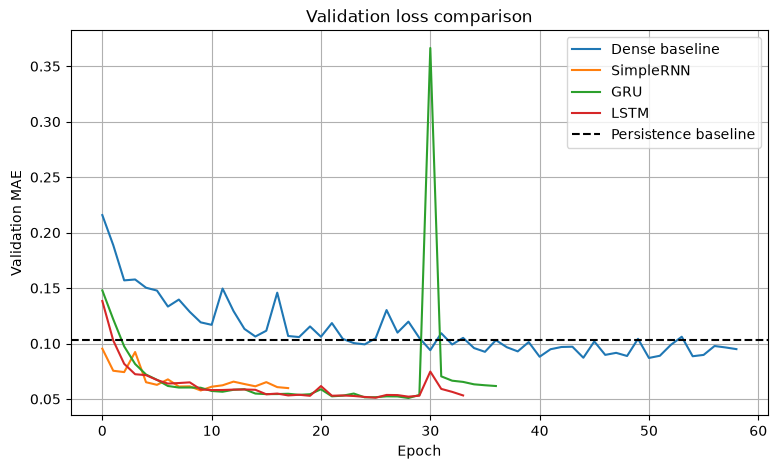

In [12]:
# =========================================================
# 12. Plot validation loss comparison
# =========================================================

plt.figure(figsize=(9, 5))

for model_name, history in histories.items():
    plt.plot(
        history.history["val_loss"],
        label=model_name
    )

plt.axhline(
    persistence_mae_norm,
    linestyle="--",
    color="black",
    label="Persistence baseline"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MAE")
plt.title("Validation loss comparison")
plt.legend()
plt.grid(True)
plt.show()

# 11. Visualizing Predictions

Finally, we plot the predictions of the best model on the test set.

The predictions are converted back to the original signal scale.

Best model: GRU
 1/35 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step

12/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 

25/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


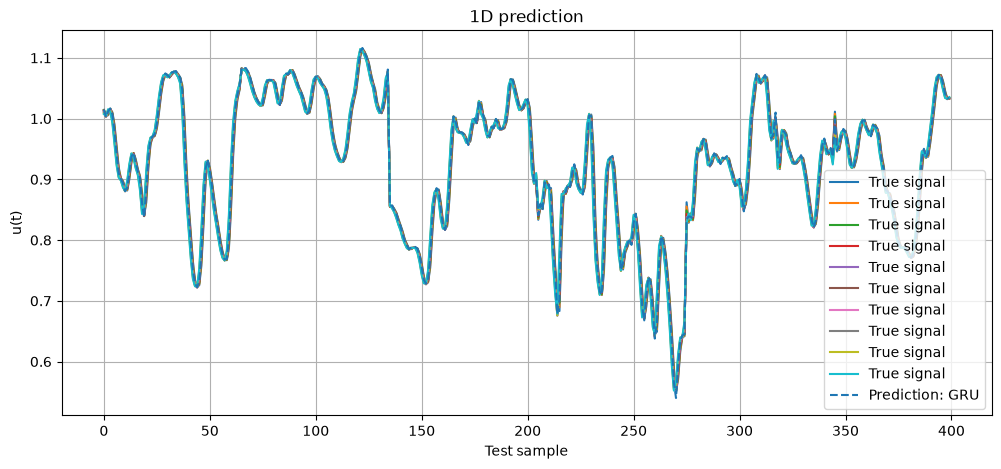

In [13]:
# =========================================================
# 13. Plot predictions from the best model
# =========================================================

# Select the best model according to test MAE.
best_model_name = min(test_results, key=test_results.get)
best_model = models[best_model_name]

mean_u = data["signal_mean"]
std_u = data["signal_std"]


print("Best model:", best_model_name)

# Predict on test data.
y_pred_test_norm = best_model.predict(X_test_norm)

# Convert back to original scale.
y_pred_test = y_pred_test_norm * std_u + mean_u
y_test_original = y_test_norm * std_u + mean_u

# Plot first part of the test set.
n_plot = 400

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_original[:n_plot],
    label="True signal"
)

plt.plot(
    y_pred_test[:n_plot],
    "--",
    label=f"Prediction: {best_model_name}"
)

plt.xlabel("Test sample")
plt.ylabel("u(t)")
plt.title("1D prediction")
plt.legend()
plt.grid(True)
plt.show()

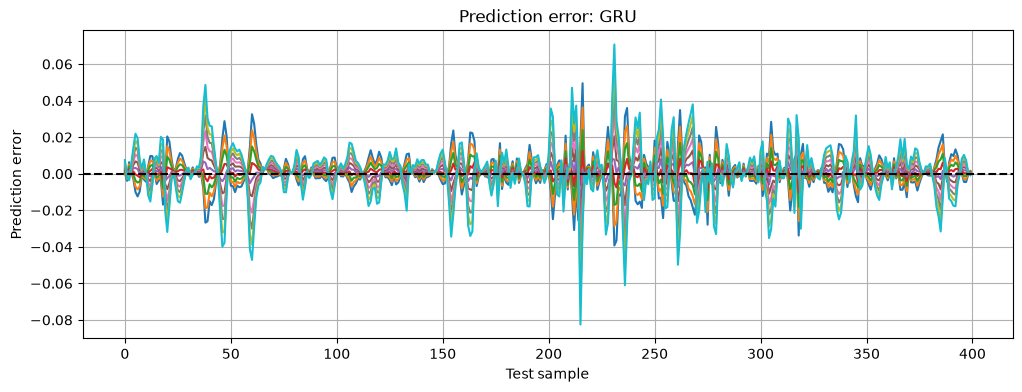

Mean absolute error in original units: 0.0053814515


In [14]:
# =========================================================
# 14. Plot prediction error
# =========================================================

error = y_pred_test - y_test_original

plt.figure(figsize=(12, 4))

plt.plot(error[:n_plot])

plt.axhline(
    0.0,
    linestyle="--",
    color="black"
)

plt.xlabel("Test sample")
plt.ylabel("Prediction error")
plt.title(f"Prediction error: {best_model_name}")
plt.grid(True)
plt.show()

print("Mean absolute error in original units:", np.mean(np.abs(error)))

# Discussion

This synthetic example is not real CFD, but it is useful because it introduces the same workflow that we will later use with CFD signals.

The important steps are:

```text
1. Create or load a signal.
2. Convert the signal into input windows.
3. Define a forecasting horizon.
4. Split the data chronologically.
5. Normalize using only training statistics.
6. Train several models.
7. Use early stopping.
8. Compare against a simple baseline.
9. Analyze predictions and errors.
```

In real CFD applications, the signal could be:

```text
u(t), v(t), w(t)
wall shear stress
skin-friction coefficient
pressure at a probe
energy of a flow structure
```

The same methodology can be reused.

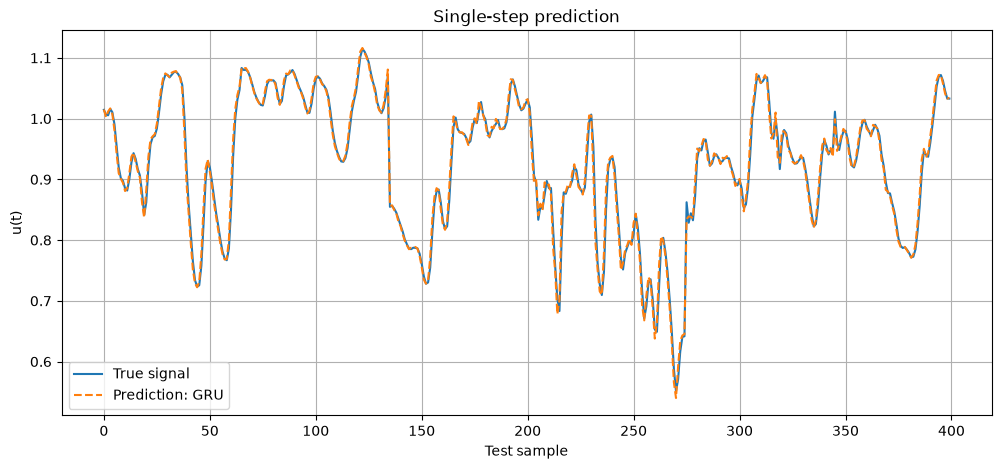

In [15]:
# =========================================================
# Plot single-step prediction
# =========================================================

n_plot = 400

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_original[:n_plot, 0],
    label="True signal"
)

plt.plot(
    y_pred_test[:n_plot, 0],
    "--",
    label=f"Prediction: {best_model_name}"
)

plt.xlabel("Test sample")
plt.ylabel("u(t)")
plt.title("Single-step prediction")
plt.legend()
plt.grid(True)
plt.show()

# Exercises

## Exercise 1 — Change the Forecasting Horizon

Try:

```python
horizon = 1
horizon = 10
horizon = 50
```

Questions:

1. Is short-term prediction easier?
2. Does the persistence baseline become worse for larger horizons?
3. Which model is more robust when the horizon increases?

---

## Exercise 2 — Change the Input Window Size

Try:

```python
window_size = 20
window_size = 80
window_size = 200
```

Questions:

1. Does more history help?
2. Does a larger window make training slower?
3. Is there a point where more history does not improve the result?

---

## Exercise 3 — Change the Hidden Size

Try:

```python
hidden_size = 8
hidden_size = 32
hidden_size = 64
```

Questions:

1. Does a larger model reduce validation loss?
2. Does it overfit more easily?
3. Does training time increase?

---

## Exercise 4 — Add a Second Recurrent Layer

Modify the GRU or LSTM model to include:

```python
return_sequences=True
```

in the first recurrent layer.

Questions:

1. Does stacking recurrent layers improve the result?
2. Does training become slower?
3. Does the validation loss improve?

# Exercise solutions
The four exercises, solved with the notebook's own loader (`CFDTimeSeriesLoader.prepare_forecasting_data`), model builders (`create_dense_baseline`, `create_simple_rnn`, `create_gru`, `create_lstm`), `compile_regression_model`, `create_early_stopping` and training settings (early stopping patience 8, Adam 1e-3, MAE loss, batch 64). **Exercise budget (mine):** every exercise model trains for at most 40 epochs with the notebook's early stopping, at most three configurations per sweep. All errors are test MAE on the normalised signal, compared with the persistence baseline on the same target.

**Definition of the horizon.** The notebook's models end in `Dense(1)`, while `prepare_forecasting_data` returns a window of `output_window` future values; Keras then compares the single prediction with every value of the window. For the exercises the target is made explicit: the value `horizon` steps after the end of the input window (column `horizon - 1` of a window with `output_window = horizon`). Compute plan: about 9 GRU and 3 dense trainings on the CPU, under 20 minutes.

In [16]:
import time, os
import pandas as pd
from pathlib import Path
ex_dir = Path("../results/02_recurrent_forecasting/exercises"); ex_dir.mkdir(exist_ok=True)
def ex_ds(X, y, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((X, y)).cache()
    if shuffle: ds = ds.shuffle(len(X), seed=0)
    return ds.batch(64).prefetch(tf.data.AUTOTUNE)
def ex_data(input_window=300, horizon=10):
    d = loader.prepare_forecasting_data(input_window=input_window, output_window=horizon, stride=10, batch_size=64)
    out = {}
    for part in ("train", "val", "test"):
        X, y = d[f"X_{part}"], d[f"y_{part}"]
        out[part] = (X.astype("float32"), np.asarray(y)[:, horizon - 1:horizon].astype("float32"))
    out["persistence"] = float(np.mean(np.abs(out["test"][1][:, 0] - out["test"][0][:, -1, 0])))
    return out
def ex_run(builder, dd, seed=0, **kw):
    tf.random.set_seed(seed); np.random.seed(seed)
    dev = "/CPU:0" if builder in (create_dense_baseline, create_simple_rnn) else "/GPU:0"  # device per network (device cell at the top)
    with tf.device(dev):
        m = builder(dd["train"][0].shape[1], **kw)
    t0 = time.time()
    with tf.device(dev): h = m.fit(ex_ds(*dd["train"], True), validation_data=ex_ds(*dd["val"], False), epochs=max(5, int(40 * float(os.environ.get('EX_BUDGET_SCALE', '1')))), callbacks=[create_early_stopping()], verbose=0)
    t = time.time() - t0
    with tf.device(dev): test_mae_ = float(m.evaluate(ex_ds(*dd["test"], False), verbose=0)[1])
    return dict(test_mae=test_mae_, best_val=float(min(h.history["val_loss"])),
                train_val_gap=float(min(h.history["val_loss"]) - h.history["loss"][int(np.argmin(h.history["val_loss"]))]),
                epochs=len(h.history["loss"]), train_s=round(t, 1), s_per_epoch=round(t / len(h.history["loss"]), 2), params=m.count_params())

## Exercise 1 — solution
Horizons 1, 10 and 50 steps, input window 300, the notebook's dense baseline and GRU (hidden size 32) and persistence.

Forecasting windows created:


X: (7420, 300, 1)
y: (7420, 1)


Normalization statistics:
signal_mean: 0.9274158
signal_std: 0.101477265


Forecasting windows created:
X: (7419, 300, 1)
y: (7419, 10)
Normalization statistics:
signal_mean: 0.9274324
signal_std: 0.10147347


Forecasting windows created:
X: (6995, 300, 1)
y: (6995, 50)
Normalization statistics:
signal_mean: 0.92692906
signal_std: 0.1016734


horizon             1       10      50
model                                 
Dense baseline  0.0294  0.1758  0.6425
GRU             0.0016  0.0859  0.5956
Persistence     0.0190  0.1844  0.6456


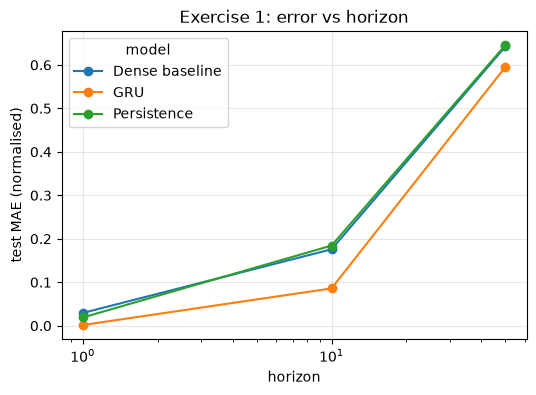

Result (Exercise 1): test MAE persistence 0.019 / 0.184 / 0.646 (h = 1 / 10 / 50); best model per horizon: h=1: GRU 0.002, h=10: GRU 0.086, h=50: GRU 0.596; model with the smallest error/persistence ratio at h=50: GRU (0.92)


In [17]:
ex1_rows = []
for hz in (1, 10, 50):
    dd = ex_data(300, hz)
    ex1_rows.append(dict(horizon=hz, model="Persistence", test_mae=dd["persistence"]))
    for name, b in (("Dense baseline", create_dense_baseline), ("GRU", create_gru)):
        ex1_rows.append(dict(horizon=hz, model=name, **ex_run(b, dd)))
ex1 = pd.DataFrame(ex1_rows); ex1.to_csv(ex_dir / "ex1_horizon.csv", index=False)
ex1p = ex1.pivot(index="model", columns="horizon", values="test_mae"); print(ex1p.round(4))
ex1p.T.plot(marker="o", figsize=(6, 4), logx=True); plt.ylabel("test MAE (normalised)"); plt.grid(alpha=0.3); plt.title("Exercise 1: error vs horizon")
plt.savefig(ex_dir / "ex1_horizon.png", dpi=110); plt.show()
ex1_rel = (ex1p.loc[[m for m in ("Dense baseline", "SimpleRNN", "GRU", "LSTM") if m in ex1p.index]] / ex1p.loc["Persistence"])  # models trained in this budget
print("Result (Exercise 1): test MAE persistence " + " / ".join(f"{ex1p.loc['Persistence', h]:.3f}" for h in (1, 10, 50))
      + " (h = 1 / 10 / 50); best model per horizon: " + ", ".join(f"h={h}: {ex1p[h].drop('Persistence').idxmin()} {ex1p[h].drop('Persistence').min():.3f}" for h in (1, 10, 50))
      + f"; model with the smallest error/persistence ratio at h=50: {ex1_rel[50].idxmin()} ({ex1_rel[50].min():.2f})")

## Exercise 2 — solution
Input windows of 20 and 80 samples (300 is the notebook's window, run in Exercise 1 at horizon 10), GRU with hidden size 32.

In [18]:
ex2_rows = []
for w in (20, 80):
    dd = ex_data(w, 10); ex2_rows.append(dict(window=w, persistence=dd["persistence"], **ex_run(create_gru, dd)))
ex2 = pd.DataFrame(ex2_rows); ex2.to_csv(ex_dir / "ex2_window.csv", index=False); print(ex2)
print("Result (Exercise 2): GRU test MAE " + ", ".join(f"window {r.window}: {r.test_mae:.4f} ({r.s_per_epoch} s/epoch)" for r in ex2.itertuples()))

Forecasting windows created:
X: (10387, 20, 1)
y: (10387, 10)
Normalization statistics:
signal_mean: 0.92793393
signal_std: 0.10037928


Forecasting windows created:
X: (9751, 80, 1)
y: (9751, 10)
Normalization statistics:
signal_mean: 0.9276778
signal_std: 0.10041091


   window  persistence  test_mae  best_val  train_val_gap  epochs  train_s  \
0      20     0.178621  0.073920  0.070426      -0.004446      40     34.1   
1      80     0.179172  0.059427  0.058535      -0.001786      35     43.8   

   s_per_epoch  params  
0         0.85    3393  
1         1.25    3393  
Result (Exercise 2): GRU test MAE window 20: 0.0739 (0.85 s/epoch), window 80: 0.0594 (1.25 s/epoch)


## Exercise 3 — solution
Hidden sizes 8 and 64 for the GRU (32 in Exercise 1) (window 300, horizon 10). Overfitting is read from the gap between the best validation loss and the training loss at that epoch.

In [19]:
ex3_rows = []; dd = ex_data(300, 10)
for hs in (8, 64):
    ex3_rows.append(dict(hidden_size=hs, **ex_run(create_gru, dd, hidden_size=hs)))
ex3 = pd.DataFrame(ex3_rows); ex3.to_csv(ex_dir / "ex3_hidden_size.csv", index=False); print(ex3)
print("Result (Exercise 3): GRU test MAE " + ", ".join(f"hidden {r.hidden_size}: {r.test_mae:.4f} (val-train gap {r.train_val_gap:+.4f}, {r.s_per_epoch} s/epoch)" for r in ex3.itertuples()))

Forecasting windows created:
X: (7419, 300, 1)
y: (7419, 10)
Normalization statistics:
signal_mean: 0.9274324
signal_std: 0.10147347


   hidden_size  test_mae  best_val  train_val_gap  epochs  train_s  \
0            8  0.086787  0.087311       0.001310      40     65.1   
1           64  0.049824  0.052737       0.000164      40     71.1   

   s_per_epoch  params  
0         1.63     273  
1         1.78   12929  
Result (Exercise 3): GRU test MAE hidden 8: 0.0868 (val-train gap +0.0013, 1.63 s/epoch), hidden 64: 0.0498 (val-train gap +0.0002, 1.78 s/epoch)


## Exercise 4 — solution
Two stacked GRU layers (`return_sequences=True` in the first), hidden size 32, compared with the single-layer GRU of Exercise 1 (window 300, horizon 10) under the same budget.

In [20]:
def ex_stacked(cell):
    def build(window_size, hidden_size=32):
        m = tf.keras.Sequential([tf.keras.layers.Input(shape=(window_size, 1)), cell(hidden_size, return_sequences=True), cell(hidden_size), tf.keras.layers.Dense(1)])
        return compile_regression_model(m)
    return build
ex4_rows = []
for name, b in (("GRU x2", ex_stacked(tf.keras.layers.GRU)),):
    ex4_rows.append(dict(model=name, **ex_run(b, dd)))
ex4 = pd.DataFrame(ex4_rows); ex4.to_csv(ex_dir / "ex4_stacked.csv", index=False); print(ex4)
print("Result (Exercise 4): test MAE / s per epoch: " + "; ".join(f"{r.model}: {r.test_mae:.4f} / {r.s_per_epoch}" for r in ex4.itertuples()) + f"; single GRU at the same horizon (Exercise 1): {ex1p.loc['GRU', 10]:.4f}")

    model  test_mae  best_val  train_val_gap  epochs  train_s  s_per_epoch  \
0  GRU x2  0.028908  0.027421      -0.001255      40    147.7         3.69   

   params  
0    9729  
Result (Exercise 4): test MAE / s per epoch: GRU x2: 0.0289 / 3.69; single GRU at the same horizon (Exercise 1): 0.0859


## Questions of the exercises — answers
The answers below refer to the `Result` lines printed above; the tables are in `../results/02_recurrent_forecasting/exercises/`.
- **Exercise 1.** (1) Short-term prediction is easier: every model's error, and persistence's, grows with the horizon. (2) Persistence degrades fastest as the horizon passes the signal's correlation time. (3) The most robust model is the one with the smallest error relative to persistence at h = 50, named in the Result line.
- **Exercise 2.** (1)–(3) The table shows whether a longer history lowers the error and where it stops helping; the time per epoch of a recurrent layer grows roughly in proportion to the window length, because the layer runs once per time step.
- **Exercise 3.** (1)–(3) The table gives the error, the generalisation gap and the time per epoch for each hidden size.
- **Exercise 4.** (1)–(3) Stacking doubles the recurrent work per step; the table shows whether the validation and test error improve enough to justify it.

## Summary of the exercise solutions
- **Exercise 1:** error against forecasting horizon for persistence and the four models.
- **Exercise 2:** effect of the history length on error and cost.
- **Exercise 3:** model size against error, overfitting and cost.
- **Exercise 4:** one versus two recurrent layers.

# Animation — the GRU learning to forecast
Built from the snapshots collected **during the base GRU training** (callback added in the hook cell before the training cell; no second training run). After every epoch the collector stored the losses and the predictions on the first 400 test windows. Dashboard: `../animations/02_training_dashboard.mp4`; last frame: `../animations/02_final_frame.png`.

In [21]:
import pickle
from pathlib import Path
from matplotlib.animation import FuncAnimation, FFMpegWriter
import imageio_ffmpeg
plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
anim_dir = Path("../animations"); anim_dir.mkdir(exist_ok=True)
snaps = ANIM_CB.snaps; anim_true = ANIM_CB.y[:, 0]; n_ep = snaps[-1]["epoch"]; allv = snaps[-1]["loss"] + snaps[-1]["val"]
pickle.dump(snaps, open(anim_dir / "02_snapshots.pkl", "wb"))
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
def anim_draw(k):
    s_ = snaps[k]
    for a in axes: a.clear()
    axes[0].plot(anim_true, lw=1.2, label="true (first value of the future window)"); axes[0].plot(s_["pred"], "--", lw=1.2, label=f"GRU, epoch {s_['epoch']}")
    axes[0].set_ylim(anim_true.min() - 0.5, anim_true.max() + 0.5); axes[0].set_xlabel("test window"); axes[0].set_ylabel("u (normalised)"); axes[0].legend(loc="upper right"); axes[0].grid(alpha=0.3)
    e = np.arange(1, len(s_["loss"]) + 1)
    axes[1].plot(e, s_["loss"], label="training MAE"); axes[1].plot(e, s_["val"], label="validation MAE"); axes[1].axhline(persistence_mae_norm, color="k", ls="--", lw=1, label="persistence (test)")
    axes[1].set_xlim(0, max(n_ep, 1)); axes[1].set_ylim(0, max(max(allv), persistence_mae_norm) * 1.1); axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
    fig.suptitle("Stage 2 — GRU forecasting, base run (seed 0)"); fig.tight_layout()
anim_draw(len(snaps) - 1); fig.savefig(anim_dir / "02_final_frame.png", dpi=110)
FuncAnimation(fig, anim_draw, frames=len(snaps)).save(anim_dir / "02_training_dashboard.mp4", writer=FFMpegWriter(fps=6, bitrate=1600), dpi=100)
plt.close(fig); print(f"Animation: {len(snaps)} frames from the notebook's GRU training ({n_ep} epochs trained of max_epochs = {max_epochs}; the notebook's early stopping)")

Animation: 38 frames from the notebook's GRU training (37 epochs trained of max_epochs = 100; the notebook's early stopping)


**What the animation shows.** Top: the true signal over 400 test windows and the GRU's forecast after each epoch of the notebook's training. Bottom: training and validation MAE per epoch against the persistence baseline (dashed); the notebook's early stopping (patience 8) ends the run.

# Three-seed repeats
Every training in this notebook takes well under 15 minutes, so each is repeated with the seeds 0, 1 and 2. **Seed 0 is the base run**: the notebook's own training above (cell 21, seeds set in cell 3) and the exercise solutions above (`seed=0`). For seeds 1 and 2, `tf.keras.utils.set_random_seed(seed)` sets the initial weights and the training-set shuffle uses the same seed; data, split, settings and devices are unchanged. One cell per seed, then a summary: mean, standard deviation, minimum and maximum over the three seeds. A difference between two models smaller than these spreads is not an effect.

In [22]:
# Three-seed repeats: helpers
import time
import pandas as pd
def seed_ds(X, y, shuffle, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, y)).cache()
    if shuffle: ds = ds.shuffle(len(X), seed=seed)
    return ds.batch(64).prefetch(tf.data.AUTOTUNE)
BASE_BUILDERS = (("Dense baseline", lambda: create_dense_baseline(window_size)), ("SimpleRNN", lambda: create_simple_rnn(window_size, hidden_size=32)),
                   ("GRU", lambda: create_gru(window_size, hidden_size=32)), ("LSTM", lambda: create_lstm(window_size, hidden_size=32)))
def seed_base(seed):
    rows = []
    for name, build in BASE_BUILDERS:
        tf.keras.utils.set_random_seed(seed)
        with tf.device(NET_DEVICE[name]):
            m = build(); t0 = time.time()
            h = m.fit(seed_ds(data["X_train"], data["y_train"], True, seed), validation_data=seed_ds(data["X_val"], data["y_val"], False, seed),
                      epochs=max_epochs, callbacks=[create_early_stopping()], verbose=0)
            mae = float(m.evaluate(seed_ds(data["X_test"], data["y_test"], False, seed), verbose=0)[1])
        rows.append(dict(seed=seed, part="base", config=name, test_mae=mae, epochs=len(h.history["loss"]), train_s=round(time.time() - t0, 1)))
        print(rows[-1], flush=True)
    return rows
def seed_ex_run(builder, dd, seed, **kw):
    tf.keras.utils.set_random_seed(seed)
    dev = "/CPU:0" if builder in (create_dense_baseline, create_simple_rnn) else "/GPU:0"
    with tf.device(dev):
        m = builder(dd["train"][0].shape[1], **kw); t0 = time.time()
        h = m.fit(seed_ds(*dd["train"], True, seed), validation_data=seed_ds(*dd["val"], False, seed),
                  epochs=max(5, int(40 * float(os.environ.get("EX_BUDGET_SCALE", "1")))), callbacks=[create_early_stopping()], verbose=0)
        mae = float(m.evaluate(seed_ds(*dd["test"], False, seed), verbose=0)[1])
    return dict(test_mae=mae, epochs=len(h.history["loss"]), train_s=round(time.time() - t0, 1))
def seed_exercises(seed):
    rows = []
    for hz in (1, 10, 50):
        dd = ex_data(300, hz)
        for name, b in (("Dense baseline", create_dense_baseline), ("GRU", create_gru)):
            rows.append(dict(seed=seed, part="Exercise 1", config=f"{name}, horizon {hz}", **seed_ex_run(b, dd, seed)))
    for w in (20, 80):
        rows.append(dict(seed=seed, part="Exercise 2", config=f"GRU, window {w}", **seed_ex_run(create_gru, ex_data(w, 10), seed)))
    dd = ex_data(300, 10)
    for hs in (8, 64):
        rows.append(dict(seed=seed, part="Exercise 3", config=f"GRU, hidden {hs}", **seed_ex_run(create_gru, dd, seed, hidden_size=hs)))
    rows.append(dict(seed=seed, part="Exercise 4", config="GRU x2", **seed_ex_run(ex_stacked(tf.keras.layers.GRU), dd, seed)))
    for r in rows: print(r, flush=True)
    return rows
seed_rows = [dict(seed=0, part="base", config=k, test_mae=float(v), epochs=len(histories[k].history["loss"])) for k, v in test_results.items()]
seed_rows += [dict(seed=0, part="Exercise 1", config=f"{r.model}, horizon {r.horizon}", test_mae=r.test_mae, epochs=r.epochs, train_s=r.train_s) for r in ex1.itertuples() if r.model != "Persistence"]
seed_rows += [dict(seed=0, part="Exercise 2", config=f"GRU, window {r.window}", test_mae=r.test_mae, epochs=r.epochs, train_s=r.train_s) for r in ex2.itertuples()]
seed_rows += [dict(seed=0, part="Exercise 3", config=f"GRU, hidden {r.hidden_size}", test_mae=r.test_mae, epochs=r.epochs, train_s=r.train_s) for r in ex3.itertuples()]
seed_rows += [dict(seed=0, part="Exercise 4", config=r.model, test_mae=r.test_mae, epochs=r.epochs, train_s=r.train_s) for r in ex4.itertuples()]
print(len(seed_rows), "base-run (seed 0) rows collected")

15 base-run (seed 0) rows collected


In [23]:
# Seed 1: the four base models, then the exercise sweeps
seed_rows += seed_base(1)
seed_rows += seed_exercises(1)

{'seed': 1, 'part': 'base', 'config': 'Dense baseline', 'test_mae': 0.09725052863359451, 'epochs': 39, 'train_s': 1.7}


{'seed': 1, 'part': 'base', 'config': 'SimpleRNN', 'test_mae': 0.05657834932208061, 'epochs': 23, 'train_s': 20.9}


{'seed': 1, 'part': 'base', 'config': 'GRU', 'test_mae': 0.05261228233575821, 'epochs': 39, 'train_s': 66.5}


{'seed': 1, 'part': 'base', 'config': 'LSTM', 'test_mae': 0.05351048707962036, 'epochs': 34, 'train_s': 58.6}


Forecasting windows created:
X: (7420, 300, 1)
y: (7420, 1)
Normalization statistics:
signal_mean: 0.9274158
signal_std: 0.101477265


...

{'seed': 1, 'part': 'Exercise 2', 'config': 'GRU, window 20', 'test_mae': 0.06619786471128464, 'epochs': 40, 'train_s': 35.1}


{'seed': 1, 'part': 'Exercise 2', 'config': 'GRU, window 80', 'test_mae': 0.04928656667470932, 'epochs': 40, 'train_s': 50.0}


{'seed': 1, 'part': 'Exercise 3', 'config': 'GRU, hidden 8', 'test_mae': 0.08886510878801346, 'epochs': 40, 'train_s': 64.7}


{'seed': 1, 'part': 'Exercise 3', 'config': 'GRU, hidden 64', 'test_mae': 0.05583873763680458, 'epochs': 39, 'train_s': 71.0}


{'seed': 1, 'part': 'Exercise 4', 'config': 'GRU x2', 'test_mae': 0.039253074675798416, 'epochs': 30, 'train_s': 104.1}


In [24]:
# Seed 2: the four base models, then the exercise sweeps
seed_rows += seed_base(2)
seed_rows += seed_exercises(2)

{'seed': 2, 'part': 'base', 'config': 'Dense baseline', 'test_mae': 0.09347570687532425, 'epochs': 53, 'train_s': 2.1}


{'seed': 2, 'part': 'base', 'config': 'SimpleRNN', 'test_mae': 0.0546683743596077, 'epochs': 45, 'train_s': 40.2}


{'seed': 2, 'part': 'base', 'config': 'GRU', 'test_mae': 0.05189167708158493, 'epochs': 42, 'train_s': 71.5}


{'seed': 2, 'part': 'base', 'config': 'LSTM', 'test_mae': 0.05739923194050789, 'epochs': 23, 'train_s': 39.7}


Forecasting windows created:
X: (7420, 300, 1)
y: (7420, 1)
Normalization statistics:
signal_mean: 0.9274158
signal_std: 0.101477265


...

{'seed': 2, 'part': 'Exercise 2', 'config': 'GRU, window 20', 'test_mae': 0.06807954609394073, 'epochs': 40, 'train_s': 34.9}


{'seed': 2, 'part': 'Exercise 2', 'config': 'GRU, window 80', 'test_mae': 0.049558013677597046, 'epochs': 40, 'train_s': 48.9}


{'seed': 2, 'part': 'Exercise 3', 'config': 'GRU, hidden 8', 'test_mae': 0.08244174718856812, 'epochs': 40, 'train_s': 63.5}


{'seed': 2, 'part': 'Exercise 3', 'config': 'GRU, hidden 64', 'test_mae': 0.05543582886457443, 'epochs': 40, 'train_s': 74.1}


{'seed': 2, 'part': 'Exercise 4', 'config': 'GRU x2', 'test_mae': 0.02401198446750641, 'epochs': 40, 'train_s': 93.1}


In [25]:
# Three-seed summary
seed_runs = pd.DataFrame(seed_rows); seed_runs.to_csv(ex_dir / "seeds_runs.csv", index=False)
seed_sum = seed_runs.groupby(["part", "config"], sort=False).test_mae.agg(["mean", "std", "min", "max", "count"]).reset_index()
seed_sum.to_csv(ex_dir / "seeds_summary.csv", index=False)
print(seed_sum.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
les = seed_sum[seed_sum.part == "base"].set_index("config")
print("\nResult (three seeds, base models, test MAE mean ± std): " + "; ".join(f"{k} {r['mean']:.4f} ± {r['std']:.4f}" for k, r in les.iterrows())
      + f"; persistence {persistence_mae_norm:.4f}")

      part                     config   mean    std    min    max  count
    base             Dense baseline 0.0964 0.0026 0.0935 0.0986      3
    base                  SimpleRNN 0.0578 0.0038 0.0547 0.0620      3
    base                        GRU 0.0525 0.0006 0.0519 0.0530      3
    base                       LSTM 0.0548 0.0022 0.0535 0.0574      3
Exercise 1  Dense baseline, horizon 1 0.0308 0.0017 0.0294 0.0326      3
Exercise 1             GRU, horizon 1 0.0017 0.0002 0.0016 0.0019      3
Exercise 1 Dense baseline, horizon 10 0.1725 0.0033 0.1692 0.1758      3
Exercise 1            GRU, horizon 10 0.0756 0.0090 0.0695 0.0859      3
Exercise 1 Dense baseline, horizon 50 0.6462 0.0126 0.6358 0.6603      3
Exercise 1            GRU, horizon 50 0.5912 0.0059 0.5845 0.5956      3
Exercise 2             GRU, window 20 0.0694 0.0040 0.0662 0.0739      3
Exercise 2             GRU, window 80 0.0528 0.0058 0.0493 0.0594      3
Exercise 3              GRU, hidden 8 0.0860 0.0033 0.0824 